In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

!pip install wfdb


import wfdb
print(wfdb.__version__)


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 163.8/163.8 kB 9.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 99.1 MB/s eta 0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.2
    Uninstalling pandas-2.2.2:
      Successfully uninstalled pandas-2.2.2
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
4.3.0


In [4]:
import wfdb

In [5]:
import numpy as np


In [6]:
import pandas as pd

In [7]:
import wfdb
import os

# Directory where data will be stored
data_dir = "mitbih_dataset"
os.makedirs(data_dir, exist_ok=True)

# Download all records (48 total) from MIT-BIH Arrhythmia Database
wfdb.dl_database('mitdb', dl_dir=data_dir)

print(" MIT-BIH Arrhythmia dataset downloaded successfully!")


Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

In [8]:
import wfdb
import numpy as np
import pandas as pd
import glob

# List all .hea files (headers) to get record names
hea_files = glob.glob(os.path.join(data_dir, "*.hea"))
record_names = [os.path.basename(f).split(".")[0] for f in hea_files]

all_signals = []
all_labels = []

for record_name in record_names:
    record = wfdb.rdrecord(os.path.join(data_dir, record_name))
    annotation = wfdb.rdann(os.path.join(data_dir, record_name), 'atr')

    signal = record.p_signal[:,0]  # use first ECG channel
    r_peaks = annotation.sample
    labels = annotation.symbol

    all_signals.append(signal)
    all_labels.append((r_peaks, labels))

print(f" Loaded {len(all_signals)} records")
print("Example signal length:", len(all_signals[0]))
print("Example labels:", all_labels[0][1][:20])


 Loaded 48 records
Example signal length: 650000
Example labels: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'N']


In [9]:
import wfdb
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

In [10]:
record_names = [
    '100', '101', '102', '103', '104', '105', '106', '107',
    '108', '109', '111', '112', '113', '114', '115', '116',
    '117', '118', '119', '121', '122', '123', '124', '200',
    '201', '202', '203', '205', '207', '208', '209', '210',
    '212', '213', '214', '215', '217', '219', '220', '221',
    '222', '223', '228', '230', '231', '232', '233', '234'
]

records = []
all_labels = []


In [11]:
records = []
all_labels = []

for name in record_names:
    annotation = wfdb.rdann(name, 'atr', pn_dir='mitdb')
    records.append(annotation)
    all_labels.extend(annotation.symbol)


In [12]:

print(f"Loaded labels for {len(record_names)} records.")

Loaded labels for 48 records.


In [13]:
label_counts = Counter(all_labels)
total_beats = sum(label_counts.values())

print("\nLabel Counts and Percentages:")
for label, count in label_counts.items():
    print(f"{label}: {count} ({count/total_beats*100:.2f}%)")



Label Counts and Percentages:
+: 1291 (1.15%)
N: 75052 (66.63%)
A: 2546 (2.26%)
V: 7130 (6.33%)
~: 616 (0.55%)
|: 132 (0.12%)
Q: 33 (0.03%)
/: 7028 (6.24%)
f: 982 (0.87%)
x: 193 (0.17%)
F: 803 (0.71%)
j: 229 (0.20%)
L: 8075 (7.17%)
a: 150 (0.13%)
J: 83 (0.07%)
R: 7259 (6.44%)
[: 6 (0.01%)
!: 472 (0.42%)
]: 6 (0.01%)
E: 106 (0.09%)
S: 2 (0.00%)
": 437 (0.39%)
e: 16 (0.01%)


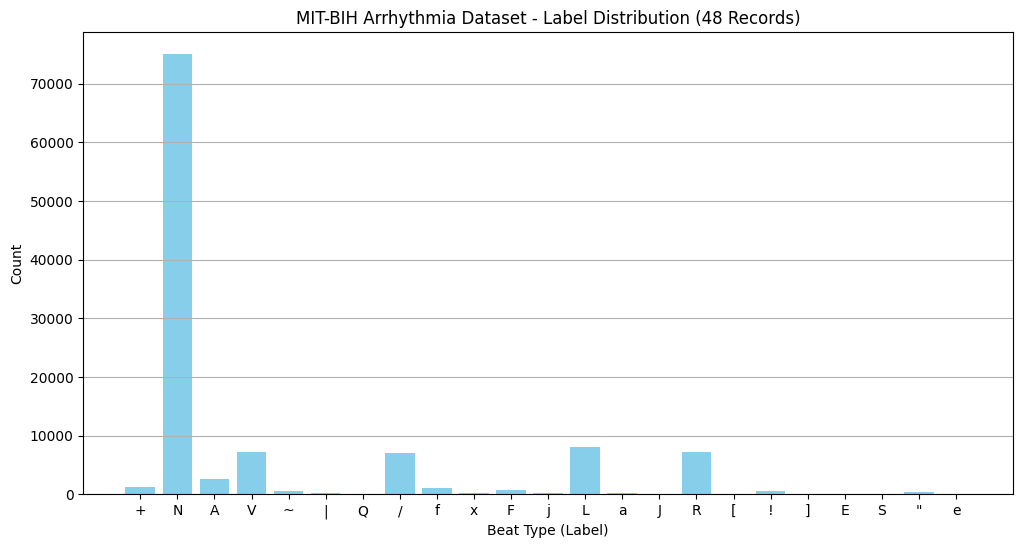

In [14]:
labels = list(label_counts.keys())
counts = [label_counts[label] for label in labels]

plt.figure(figsize=(12,6))
plt.bar(labels, counts, color='skyblue')
plt.xlabel("Beat Type (Label)")
plt.ylabel("Count")
plt.title("MIT-BIH Arrhythmia Dataset - Label Distribution (48 Records)")
plt.grid(axis='y')
plt.show()

In [15]:
import wfdb
import os
import numpy as np
import glob
data_dir = "mitbih_dataset"
window_size = 360   # 180 before + 180 after R peak
half_window = window_size // 2

# AAMI 5-class label mapping
label_map = {
    # N class (Normal)
    'N': 'N', 'L': 'N', 'R': 'N', 'e': 'N', 'j': 'N',
    # S class (Supraventricular)
    'A': 'S', 'a': 'S', 'J': 'S', 'S': 'S',
    # V class (Ventricular)
    'V': 'V', 'E': 'V',
    # F class (Fusion)
    'F': 'F',
    # Q class (Unknown/Other)
    '/': 'Q', 'f': 'Q', 'Q': 'Q', '?': 'Q', '~': 'Q',
    '|': 'Q', '!': 'Q', '[': 'Q', ']': 'Q', 'x': 'Q',
    '(': 'Q', ')': 'Q', 'p': 'Q'
}

hea_files = glob.glob(os.path.join(data_dir, "*.hea"))
record_names = [os.path.basename(f).split(".")[0] for f in hea_files]

print(f"Found {len(record_names)} records in MIT-BIH")

X_beats = []
y_labels = []

for record_name in record_names:
    print(f"Processing record: {record_name}")

    record = wfdb.rdrecord(os.path.join(data_dir, record_name))
    annotation = wfdb.rdann(os.path.join(data_dir, record_name), 'atr')

    signal = record.p_signal[:, 0]   # First channel (MLII usually)
    r_peaks = annotation.sample
    symbols = annotation.symbol

    for idx, r in enumerate(r_peaks):
        label = symbols[idx]

        # Skip if label not in AAMI map
        if label not in label_map:
            continue

        # Extract beat window
        start = r - half_window
        end = r + half_window

        if start < 0 or end > len(signal):
            continue  # skip beats near edges

        beat = signal[start:end]

        # Normalize (zero mean, unit variance)
        beat = (beat - np.mean(beat)) / (np.std(beat) + 1e-8)

        X_beats.append(beat)
        y_labels.append(label_map[label])

print(f" Extracted {len(X_beats)} beats total")
print("Example beat shape:", X_beats[0].shape)
print("Example label:", y_labels[0])


Found 48 records in MIT-BIH
Processing record: 121
Processing record: 231
Processing record: 228
Processing record: 221
Processing record: 202
Processing record: 205
Processing record: 233
Processing record: 124
Processing record: 217
Processing record: 232
Processing record: 103
Processing record: 117
Processing record: 115
Processing record: 111
Processing record: 106
Processing record: 104
Processing record: 212
Processing record: 112
Processing record: 116
Processing record: 210
Processing record: 223
Processing record: 203
Processing record: 200
Processing record: 114
Processing record: 213
Processing record: 109
Processing record: 118
Processing record: 208
Processing record: 107
Processing record: 122
Processing record: 108
Processing record: 113
Processing record: 222
Processing record: 119
Processing record: 101
Processing record: 209
Processing record: 219
Processing record: 102
Processing record: 100
Processing record: 201
Processing record: 105
Processing record: 215
Proces

In [16]:

label_classes = ['N', 'S', 'V', 'F', 'Q']
label_to_int = {l: i for i, l in enumerate(label_classes)}
y_encoded = np.array([label_to_int[l] for l in y_labels])

X_array = np.array(X_beats)
X_array = X_array[..., np.newaxis]
y_array = y_encoded

print("Final dataset shapes:")
print("X:", X_array.shape)
print("y:", y_array.shape)
print("Class distribution:", {c: sum(y_array==i) for i,c in enumerate(label_classes)})
np.save("X_mitbih.npy", X_array)
np.save("y_mitbih.npy", y_array)

print(" Saved preprocessed dataset: X_mitbih.npy, y_mitbih.npy")


Final dataset shapes:
X: (110861, 360, 1)
y: (110861,)
Class distribution: {'N': np.int64(90582), 'S': np.int64(2781), 'V': np.int64(7235), 'F': np.int64(802), 'Q': np.int64(9461)}
 Saved preprocessed dataset: X_mitbih.npy, y_mitbih.npy


In [17]:
import numpy as np
from sklearn.model_selection import train_test_split
import pandas as pd
X = np.load("X_mitbih.npy")   # shape (110861, 360, 1)
y = np.load("y_mitbih.npy")   # shape (110861,)

print("Dataset loaded:")
print("X shape:", X.shape)
print("y shape:", y.shape)
classes = ['N', 'S', 'V', 'F', 'Q']
class_counts = {c: sum(y == i) for i, c in enumerate(classes)}
print("Class distribution:", class_counts)
df = pd.DataFrame(list(class_counts.items()), columns=["Class", "Count"])
print(df)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train shape:", X_train.shape, y_train.shape)
print("Test shape:", X_test.shape, y_test.shape)


Dataset loaded:
X shape: (110861, 360, 1)
y shape: (110861,)
Class distribution: {'N': np.int64(90582), 'S': np.int64(2781), 'V': np.int64(7235), 'F': np.int64(802), 'Q': np.int64(9461)}
  Class  Count
0     N  90582
1     S   2781
2     V   7235
3     F    802
4     Q   9461
Train shape: (88688, 360, 1) (88688,)
Test shape: (22173, 360, 1) (22173,)


In [19]:
import numpy as np

X = np.load("/content/X_mitbih.npy")
y = np.load("/content/y_mitbih.npy")

print("X shape:", X.shape)
print("y shape:", y.shape)

print("First 10 values of X[0]:")
print(X[0][:10])


X shape: (110861, 360, 1)
y shape: (110861,)
First 10 values of X[0]:
[[-0.42865426]
 [-0.45632425]
 [-0.48399424]
 [-0.48399424]
 [-0.51166423]
 [-0.53933422]
 [-0.5946742 ]
 [-0.62234419]
 [-0.62234419]
 [-0.56700421]]


In [20]:
import numpy as np
import plotly.graph_objects as go

X = np.load("/content/X_mitbih.npy")
y = np.load("/content/y_mitbih.npy")
i = 0
signal = X[i].flatten()
fig = go.Figure()
fig.add_trace(go.Scatter(y=signal, mode='lines', name=f"Label: {y[i]}"))

fig.update_layout(
    title=f"ECG Signal Index {i} | Label: {y[i]}",
    xaxis_title="Sample Index",
    yaxis_title="Amplitude",
    template="plotly_white"
)

fig.show()


In [21]:
import numpy as np

X = np.load("X_mitbih.npy")
y = np.load("y_mitbih.npy")

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (110861, 360, 1)
y shape: (110861,)


In [88]:
import torch

print(torch.__version__)
print(torch.version.cuda)
print(torch.backends.cudnn.version())
print(torch.cuda.is_available())

2.9.0+cu126
12.6
91002
True


In [89]:
import numpy as np

X = np.load("X_mitbih.npy")
y = np.load("y_mitbih.npy")

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (110861, 360, 1)
y shape: (110861,)


In [90]:
from sklearn.model_selection import train_test_split
import torch

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.long)
X_test  = torch.tensor(X_test,  dtype=torch.float32)
y_test  = torch.tensor(y_test,  dtype=torch.long)


In [91]:
from torch.utils.data import WeightedRandomSampler

class_sample_count = np.array([len(np.where(y_train.numpy()==t)[0]) for t in np.unique(y_train.numpy())])
print("Class counts:", class_sample_count)

weight = 1. / class_sample_count
samples_weight = np.array([weight[t] for t in y_train.numpy()])

samples_weight = torch.from_numpy(samples_weight)
sampler = WeightedRandomSampler(samples_weight, len(samples_weight), replacement=True)


Class counts: [72465  2225  5788   641  7569]


In [92]:
from torch.utils.data import Dataset, DataLoader

class ECGDataset(Dataset):
    def __init__(self, X, y):
        self.X = X
        self.y = y

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(ECGDataset(X_train, y_train), batch_size=64, sampler=sampler)
test_loader  = DataLoader(ECGDataset(X_test,  y_test),  batch_size=64, shuffle=False)


In [113]:
class CNN1D(nn.Module):
    def __init__(self, input_length, num_classes=5, dropout_p=0.5):  # increased dropout
        super(CNN1D, self).__init__()

        self.conv1 = nn.Conv1d(1, 32, kernel_size=5, padding=2)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(2)
        self.drop1 = nn.Dropout(dropout_p)

        self.conv2 = nn.Conv1d(32, 64, 5, padding=2)
        self.bn2 = nn.BatchNorm1d(64)
        self.pool2 = nn.MaxPool1d(2)
        self.drop2 = nn.Dropout(dropout_p)

        self.conv3 = nn.Conv1d(64, 128, 5, padding=2)
        self.bn3 = nn.BatchNorm1d(128)
        self.pool3 = nn.MaxPool1d(2)
        self.drop3 = nn.Dropout(dropout_p)

        self.flattened_size = 128 * (input_length // 8)

        self.fc1 = nn.Linear(self.flattened_size, 128)  # reduced FC size
        self.drop_fc1 = nn.Dropout(dropout_p)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(x)
        x = self.drop1(x)

        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool2(x)
        x = self.drop2(x)

        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool3(x)
        x = self.drop3(x)

        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.drop_fc1(x)
        x = self.fc2(x)
        return x



In [114]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)

CNN1D(
  (conv1): Conv1d(1, 32, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn1): BatchNorm1d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop1): Dropout(p=0.5, inplace=False)
  (conv2): Conv1d(32, 64, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn2): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop2): Dropout(p=0.5, inplace=False)
  (conv3): Conv1d(64, 128, kernel_size=(5,), stride=(1,), padding=(2,))
  (bn3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (pool3): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (drop3): Dropout(p=0.5, inplace=False)
  (fc1): Linear(in_features=5760, out_features=256, bias=True)
  (drop_fc1): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_featu

In [115]:

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-3)  # stronger weight decay
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)


In [125]:
import torch
from tqdm import tqdm
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
num_epochs = 50
best_loss = float("inf")
train_losses = []
val_losses = []
train_acc_list = []
val_acc_list = []
lr_list = []
early_stop_patience = 5
epochs_no_improve = 0
early_stop_start = 25  # start early stopping earlier

print("\nStarting training the model...\n")
for epoch in range(num_epochs):
    model.train()
    total_train_loss = 0.0

    for Xb, yb in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}", leave=False):
        Xb, yb = Xb.to(device), yb.to(device)

        optimizer.zero_grad()
        preds = model(Xb)
        loss = criterion(preds, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # gradient clipping
        optimizer.step()

        total_train_loss += loss.item() * Xb.size(0)  # sum weighted by batch size

    avg_train_loss = total_train_loss / len(train_loader.dataset)

    # --- Validation ---
    model.eval()
    total_val_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for Xt, yt in test_loader:
            Xt, yt = Xt.to(device), yt.to(device)
            preds = model(Xt)
            loss = criterion(preds, yt)
            total_val_loss += loss.item() * Xt.size(0)
            predicted = preds.argmax(dim=1)
            correct += (predicted == yt).sum().item()
            total += yt.size(0)

    avg_val_loss = total_val_loss / len(test_loader.dataset)
    val_acc = correct / total
    scheduler.step(avg_val_loss)

    train_losses.append(avg_train_loss)
    val_losses.append(avg_val_loss)

    if avg_val_loss < best_loss:
        best_loss = avg_val_loss
        torch.save(model.state_dict(), "best_cnn_arrhythmia.pt")
        epochs_no_improve = 0
    else:
        if epoch >= early_stop_start:
            epochs_no_improve += 1
    if epoch >= early_stop_start and epochs_no_improve >= early_stop_patience:
        print(f"Early stopping triggered after {epoch+1} epochs.")
        break

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {avg_train_loss:.4f} | "
          f"Val Loss: {avg_val_loss:.4f} | "
          f"Accuracy: {val_acc:.4f}")

print("\nTraining Completed!")
print("Best model saved as: best_cnn_arrhythmia.pt")



Starting training the model...



Epoch 1/50 | Train Loss: 0.0787 | Val Loss: 0.0698 | Accuracy: 0.9782


Epoch 2/50 | Train Loss: 0.0756 | Val Loss: 0.0762 | Accuracy: 0.9756


Epoch 3/50 | Train Loss: 0.0725 | Val Loss: 0.0666 | Accuracy: 0.9797


Epoch 4/50 | Train Loss: 0.0746 | Val Loss: 0.0749 | Accuracy: 0.9766


Epoch 5/50 | Train Loss: 0.0734 | Val Loss: 0.0656 | Accuracy: 0.9811


... (24 outputs left out)

Epoch 30/50 | Train Loss: 0.0693 | Val Loss: 0.0676 | Accuracy: 0.9792


Epoch 31/50 | Train Loss: 0.0672 | Val Loss: 0.0662 | Accuracy: 0.9795


Epoch 32/50 | Train Loss: 0.0691 | Val Loss: 0.0662 | Accuracy: 0.9794


Early stopping triggered after 33 epochs.

Training Completed!
Best model saved as: best_cnn_arrhythmia.pt


In [118]:
torch.save(model.state_dict(), "best_cnn_arrhythmia.pt")


In [119]:
import os
print("Current directory:", os.getcwd())
print(os.listdir(os.getcwd()))


Current directory: /content
['.config', 'y_mitbih.npy', 'drive', 'X_mitbih.npy', 'best_cnn_arrhythmia.pt', 'mitbih_dataset', 'sample_data']


In [120]:
from google.colab import files
files.download("best_cnn_arrhythmia.pt")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

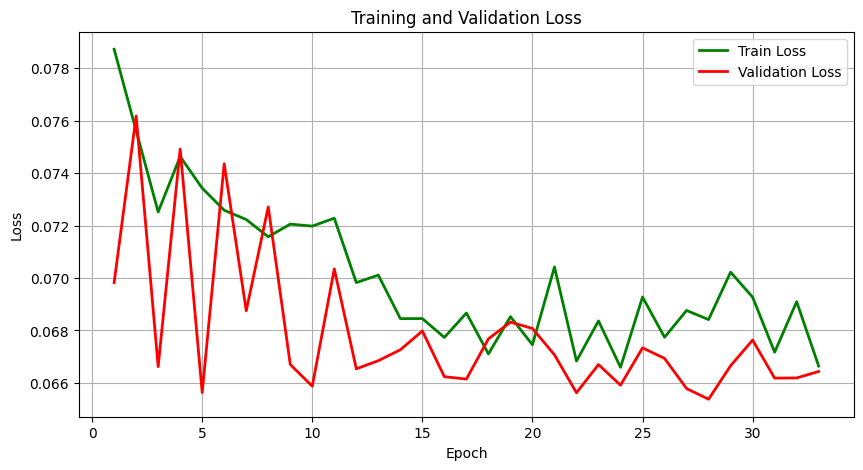

In [126]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(10, 5))
plt.plot(epochs, train_losses, label="Train Loss", color="green", linewidth=2)
plt.plot(epochs, val_losses, label="Validation Loss", color="red", linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
import torch
import numpy as np

model.eval()

all_preds = []
all_labels = []
all_probs = []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        yb = yb.to(device)

        out = model(xb)                    
        prob = torch.softmax(out, dim=1)   
        preds = torch.argmax(prob, dim=1)  

        all_labels.extend(yb.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(prob.cpu().numpy())


In [135]:
class_names = [
    "Normal (N)",
    "SVEB",
    "VEB",
    "Fusion (F)",
    "Unknown (Q)"
]


<Figure size 800x800 with 0 Axes>

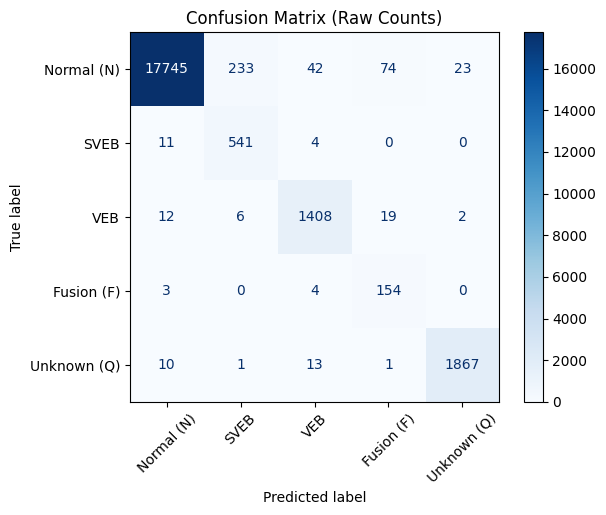

In [136]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(8, 8))
disp = ConfusionMatrixDisplay(cm, display_labels=class_names)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion Matrix (Raw Counts)")
plt.xticks(rotation=45)
plt.show()


<Figure size 800x800 with 0 Axes>

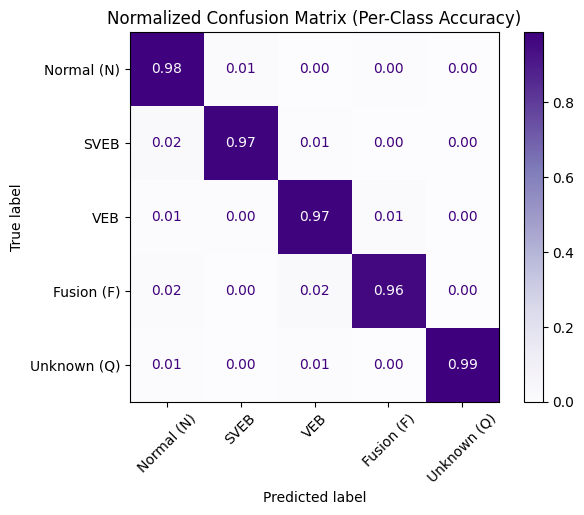

In [137]:
cm_norm = confusion_matrix(all_labels, all_preds, normalize='true')

plt.figure(figsize=(8, 8))
disp = ConfusionMatrixDisplay(cm_norm, display_labels=class_names)
disp.plot(cmap="Purples", values_format=".2f")
plt.title("Normalized Confusion Matrix (Per-Class Accuracy)")
plt.xticks(rotation=45)
plt.show()


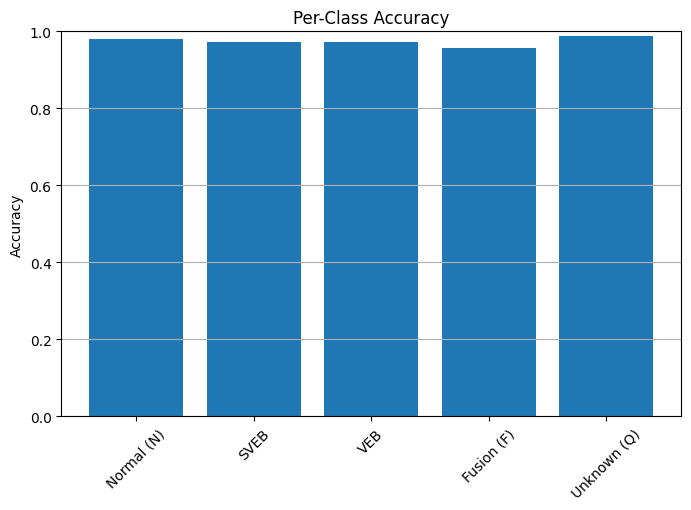

In [138]:
class_accuracies = cm.diagonal() / cm.sum(axis=1)

plt.figure(figsize=(8, 5))
plt.bar(class_names, class_accuracies)
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.title("Per-Class Accuracy")
plt.grid(axis="y")
plt.xticks(rotation=45)
plt.show()


In [140]:
from sklearn.metrics import classification_report

print("\nClassification Report:\n")
print(classification_report(all_labels, all_preds, target_names=class_names))



Classification Report:

              precision    recall  f1-score   support

  Normal (N)       1.00      0.98      0.99     18117
        SVEB       0.69      0.97      0.81       556
         VEB       0.96      0.97      0.97      1447
  Fusion (F)       0.62      0.96      0.75       161
 Unknown (Q)       0.99      0.99      0.99      1892

    accuracy                           0.98     22173
   macro avg       0.85      0.97      0.90     22173
weighted avg       0.98      0.98      0.98     22173



In [ ]:

classes = ['N', 'SVEB', 'VEB', 'F', 'Q'] 
all_preds_labels = [classes[i] for i in all_preds]
all_labels_labels = [classes[i] for i in all_labels]


In [ ]:


y_pred_binary = np.where(np.isin(all_preds_labels, ['SVEB', 'VEB', 'F', 'Q']), 1, 0)
y_true_binary = np.where(np.isin(all_labels_labels, ['SVEB', 'VEB', 'F', 'Q']), 1, 0)

Confusion Matrix – Beat-level Arrhythmia Detection:
[[17745   372]
 [   36  4020]]


<Figure size 600x600 with 0 Axes>

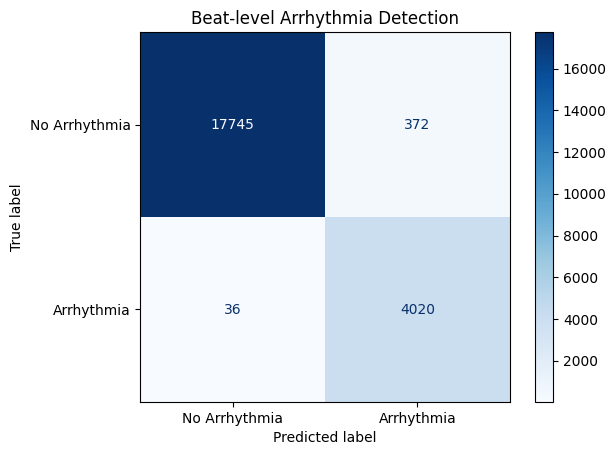

In [ ]:


cm = confusion_matrix(y_true_binary, y_pred_binary)
print("Confusion Matrix – Beat-level Arrhythmia Detection:")
print(cm)

plt.figure(figsize=(6, 6))
disp = ConfusionMatrixDisplay(cm, display_labels=["No Arrhythmia", "Arrhythmia"])
disp.plot(cmap="Blues", values_format="d")
plt.title("Beat-level Arrhythmia Detection")
plt.show()

In [ ]:

print("\nClassification Report – Beat-level Arrhythmia Detection:")
print(classification_report(y_true_binary, y_pred_binary, target_names=["No Arrhythmia", "Arrhythmia"]))



Classification Report – Beat-level Arrhythmia Detection:
               precision    recall  f1-score   support

No Arrhythmia       1.00      0.98      0.99     18117
   Arrhythmia       0.92      0.99      0.95      4056

     accuracy                           0.98     22173
    macro avg       0.96      0.99      0.97     22173
 weighted avg       0.98      0.98      0.98     22173



In [ ]:
def predict_beat(beat, model, device, input_length=360):
    """
    Predict if a single beat is Normal (0) or Arrhythmia (1)
    """
    import torch
    import numpy as np
    model.eval()

   
    if isinstance(beat, np.ndarray):
        beat_tensor = torch.tensor(beat, dtype=torch.float32)
    else:
        beat_tensor = beat.float()

    beat_tensor = beat_tensor.view(-1)

  
    if beat_tensor.numel() < input_length:
        pad_size = input_length - beat_tensor.numel()
        beat_tensor = torch.cat([beat_tensor, torch.zeros(pad_size)], dim=0)
    elif beat_tensor.numel() > input_length:
        beat_tensor = beat_tensor[:input_length]

   
    beat_tensor = beat_tensor.unsqueeze(0).unsqueeze(0).to(device)

   
    with torch.no_grad():
        output = model(beat_tensor)
        pred = torch.argmax(output, dim=1).item()

    return pred


In [192]:
arrhythmia_indices = []

for i, beat in enumerate(X_test):
    pred = predict_beat(beat, model, device)
    if pred == 1:  # 1 = Arrhythmia
        arrhythmia_indices.append(i)

print("Beat indices with Arrhythmia:", arrhythmia_indices)


Beat indices with Arrhythmia: [32, 33, 43, 63, 67, 108, 142, 203, 224, 249, 265, 282, 302, 303, 308, 315, 319, 328, 344, 368, 388, 400, 406, 408, 420, 451, 456, 467, 472, 518, 561, 565, 567, 574, 581, 772, 791, 806, 829, 894, 920, 973, 976, 1000, 1009, 1013, 1055, 1070, 1086, 1120, 1189, 1203, 1246, 1262, 1274, 1302, 1316, 1379, 1381, 1423, 1428, 1490, 1503, 1518, 1539, 1542, 1663, 1676, 1693, 1714, 1748, 1820, 1872, 1908, 1911, 1927, 1937, 1967, 1972, 1980, 2004, 2016, 2106, 2125, 2190, 2206, 2230, 2231, 2239, 2248, 2321, 2335, 2364, 2366, 2391, 2408, 2454, 2471, 2472, 2480, 2482, 2501, 2503, 2555, 2584, 2603, 2620, 2668, 2699, 2829, 2860, 2870, 2881, 2897, 2932, 2941, 2944, 2948, 3072, 3095, 3118, 3155, 3211, 3229, 3257, 3262, 3290, 3321, 3358, 3367, 3368, 3382, 3451, 3477, 3575, 3637, 3641, 3642, 3655, 3665, 3704, 3744, 3764, 3825, 3835, 3896, 3918, 3928, 3971, 3976, 4012, 4134, 4139, 4141, 4183, 4194, 4206, 4212, 4219, 4290, 4354, 4381, 4403, 4447, 4530, 4590, 4647, 4658, 4681, 470

In [198]:
beat_index = int(input("Enter beat index to check: "))
beat = X_test[beat_index]

prediction = predict_beat(beat, model, device)

if prediction == 0:
    print(f"The Person is  {beat_index} → Normal")
else:
    print(f"The Person has {beat_index} → Arrhythmia")


Enter beat index to check: 33
The Person has 33 → Arrhythmia


In [199]:
import torch
torch.save(model, "cnn_arrhythmia_full_model.pt")
torch.save(model.state_dict(), "cnn_arrhythmia_state_dict.pt")

print("Model saved successfully!")


Model saved successfully!


In [ ]:
import torch
import numpy as np
import torch.nn as nn
import torch.nn.functional as F

X_test = np.load("X_mitbih.npy")  

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class CNN1D(nn.Module):
    def __init__(self, input_length):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 32, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(2)
        self.conv2 = nn.Conv1d(32, 64, 5, padding=2)
        self.bn2 = nn.BatchNorm1d(64)
        self.pool2 = nn.MaxPool1d(2)
        self.conv3 = nn.Conv1d(64, 128, 5, padding=2)
        self.bn3 = nn.BatchNorm1d(128)
        self.pool3 = nn.MaxPool1d(2)
        self.flattened_size = 128 * (input_length // 8)
        self.fc1 = nn.Linear(self.flattened_size, 128)
        self.fc2 = nn.Linear(128, 2)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(x)
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool2(x)
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool3(x)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.fc2(x)
        return x

# --- Load saved model state_dict ---
input_length = X_test.shape[1]
model = CNN1D(input_length=input_length)
model.load_state_dict(torch.load("best_cnn_arrhythmia.pt", map_location=device))
model.to(device)
model.eval()

# --- Prediction function ---
def predict_beat(beat):
    if isinstance(beat, np.ndarray):
        beat = torch.tensor(beat, dtype=torch.float32)
    beat = beat.view(1, 1, -1).to(device)
    with torch.no_grad():
        output = model(beat)
        return torch.argmax(output, dim=1).item()

# --- Instant user input ---
beat_index = int(input("Enter beat index to check: "))
beat = X_test[beat_index]
prediction = predict_beat(beat)

if prediction == 0:
    print(f"Beat index {beat_index} → Normal")
else:
    print(f"Beat index {beat_index} → Arrhythmia")


RuntimeError: Error(s) in loading state_dict for CNN1D:
	size mismatch for fc1.weight: copying a param with shape torch.Size([256, 5760]) from checkpoint, the shape in current model is torch.Size([128, 5760]).
	size mismatch for fc1.bias: copying a param with shape torch.Size([256]) from checkpoint, the shape in current model is torch.Size([128]).
	size mismatch for fc2.weight: copying a param with shape torch.Size([5, 256]) from checkpoint, the shape in current model is torch.Size([2, 128]).
	size mismatch for fc2.bias: copying a param with shape torch.Size([5]) from checkpoint, the shape in current model is torch.Size([2]).

In [210]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

X_test = np.load("X_mitbih.npy")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# --- Define CNN exactly as in training ---
class CNN1D(nn.Module):
    def __init__(self, input_length, num_classes=5):
        super().__init__()
        self.conv1 = nn.Conv1d(1, 32, 5, padding=2)
        self.bn1 = nn.BatchNorm1d(32)
        self.pool1 = nn.MaxPool1d(2)
        self.drop1 = nn.Dropout(0.5)
        self.conv2 = nn.Conv1d(32, 64, 5, padding=2)
        self.bn2 = nn.BatchNorm1d(64)
        self.pool2 = nn.MaxPool1d(2)
        self.drop2 = nn.Dropout(0.5)
        self.conv3 = nn.Conv1d(64, 128, 5, padding=2)
        self.bn3 = nn.BatchNorm1d(128)
        self.pool3 = nn.MaxPool1d(2)
        self.drop3 = nn.Dropout(0.5)
        self.flattened_size = 128 * (input_length // 8)
        self.fc1 = nn.Linear(self.flattened_size, 256)  # matches saved model
        self.drop_fc1 = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.pool1(x)
        x = self.drop1(x)
        x = F.relu(self.bn2(self.conv2(x)))
        x = self.pool2(x)
        x = self.drop2(x)
        x = F.relu(self.bn3(self.conv3(x)))
        x = self.pool3(x)
        x = self.drop3(x)
        x = x.view(x.size(0), -1)
        x = F.relu(self.fc1(x))
        x = self.drop_fc1(x)
        x = self.fc2(x)
        return x

# --- Load the saved model state ---
input_length = X_test.shape[1]
model = CNN1D(input_length=input_length)
model.load_state_dict(torch.load("best_cnn_arrhythmia.pt", map_location=device))
model.to(device)
model.eval()

# --- Prediction function (map original 5 classes to 2 classes) ---
def predict_beat(beat):
    if isinstance(beat, np.ndarray):
        beat = torch.tensor(beat, dtype=torch.float32)
    beat = beat.view(1, 1, -1).to(device)
    with torch.no_grad():
        output = model(beat)
        pred_class = torch.argmax(output, dim=1).item()
        # Map to 0=Normal, 1=Arrhythmia
        if pred_class == 0:
            return 0
        else:
            return 1

# --- Instant input ---
beat_index = int(input("Enter beat index to check: "))
beat = X_test[beat_index]
prediction = predict_beat(beat)
print(f"Beat index {beat_index} → {'Normal' if prediction==0 else 'Arrhythmia'}")


Enter beat index to check: 15
Beat index 15 → Normal
